# Aligning male and female mouse kidney sections from Cartana

In this notebook, we align two single cell resolution spatial transcriptomics datasets of sham-operated adult mouse kidney sections, assayed by Cartana in situ sequencing and segmented with Baysor from [Wu et al](https://www.nature.com/articles/s41467-024-45752-8): a male section ([GSM7090410](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM7090410)) as the source and a female section ([GSM7090415](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM7090415)) as the target.

In [1]:
## import dependencies
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import STalign

# make plots bigger
plt.rcParams["figure.figsize"] = (12,10)

## Read in and format the input

Each dataset is a Baysor `segmentation_cell_stats.csv` file, which we have compressed and placed in a folder called `cartana_data`. It has one row per cell, with the cell centroid in the `x` and `y` columns.

`STalign` needs the cell centroids as numpy arrays. Its defaults assume micrometers, while Baysor reports image pixels, so we convert them. The pixel size is not stated in the data release; 0.1625 µm per pixel gives a section of about 4.4 × 5.8 mm, consistent with mouse kidney.

In [2]:
# micrometers per image pixel (assumed)
um_per_px = 0.1625

# source (male) and target (female) cells
df1 = pd.read_csv('../cartana_data/GSM7090410_cartana_sham_male_segmentation_cell_stats.csv.gz')
df2 = pd.read_csv('../cartana_data/GSM7090415_cartana_sham_female_segmentation_cell_stats.csv.gz')
print(df1.head())

# cell centroids in um
xI = df1['x'].to_numpy()*um_per_px
yI = df1['y'].to_numpy()*um_per_px
xJ = df2['x'].to_numpy()*um_per_px
yJ = df2['y'].to_numpy()*um_per_px

   cell            x            y  cluster  n_transcripts   density  \
0     1  5905.766000  4884.044000        4              5  0.007945   
1     2  5086.160000  5708.391250        5              8  0.011020   
2     3  5556.215000  5281.355000        6             10  0.005935   
3     4  5017.552000  5799.638000        5             10  0.010640   
4     5  6035.902857  4798.607143        5              7  0.007109   

   elongation    area  avg_confidence  
0       5.859   629.3          0.9994  
1       1.989   725.7          0.9999  
2       2.592  1685.0          1.0000  
3       3.218   940.2          1.0000  
4       4.155   984.7          0.9992  


Both sections already have the papilla pointing down, so no initial rotation is needed. We only move the source cells so that their centroid is on the target's, which gives the alignment a good starting point.

In [3]:
# move the centroid of the source cells onto the centroid of the target cells
xI = xI - xI.mean() + xJ.mean()
yI = yI - yI.mean() + yJ.mean()

## Before alignment

Image coordinates have their origin at the top left, so we invert the y axis.

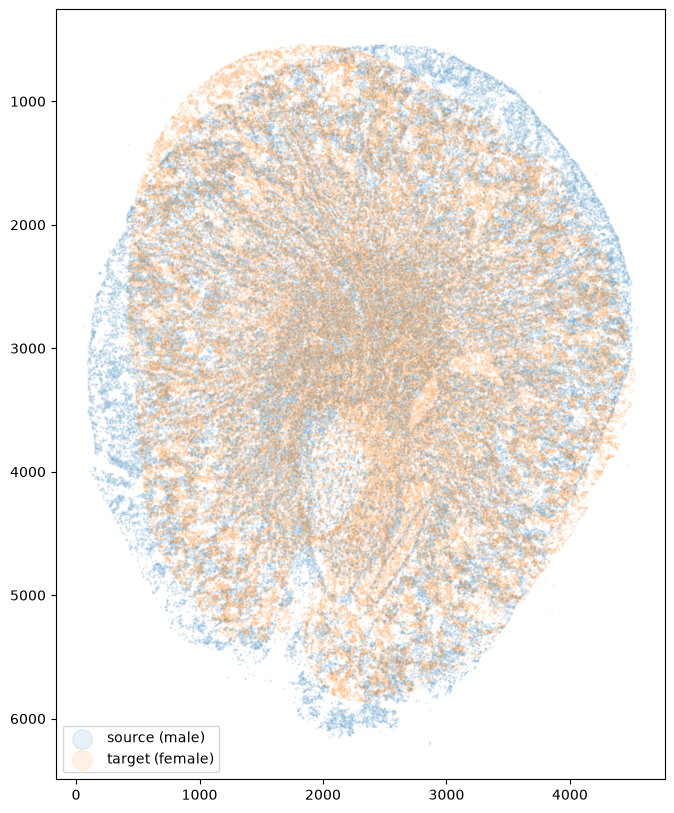

In [4]:
fig,ax = plt.subplots()
ax.scatter(xI,yI,s=0.5,alpha=0.1, label='source (male)')
ax.scatter(xJ,yJ,s=0.5,alpha=0.1, label='target (female)')
ax.set_aspect('equal')
ax.invert_yaxis()
ax.legend(markerscale = 20, loc = 'lower left')

## Alignment and diagnostic plots

`align_cells` rasterizes both sets of cells into density images and runs `LDDMM` on them, coarse to fine. Several options differ from the defaults here:

* `dx=30`: rasterize at 30 µm instead of 15 µm. Coarser images are faster to fit and smooth out cell-to-cell variation that does not help a whole-section alignment, while 30 µm still resolves the tissue boundary (50 µm matched the outline of the section less well).
* `levels=((2,1000),(1,3000))`: the coarse-to-fine schedule, as (pooling factor, iterations) pairs. We run 1000 iterations on the images pooled to 60 µm, then 3000 at the full 30 µm. The default, ((4,500),(2,500)), would pool 30 µm images to 120 and 60 µm, and 500 iterations is not enough for the energy to level off.
* `mixture=None`: the default mixture model allows for tissue missing from the target, but the female section is complete.
* `prefit=False`: by default `LDDMM` first fits an affine transform from several starting angles. For these sections it picked a 30° start that ended in a stretch of about 30% along one axis, so we start from the centroid shift above instead.

`align_cells` draws `LDDMM`'s diagnostic figures for its last, finest level:

* the smoothing kernel of the velocity field;
* the source deformed onto the target (before and after its intensities are matched to the target's), the target, the velocity field, the matching weights of the target pixels, and the remaining error, which should show no large structure;
* the energy over the iterations: `E` is the total, `EM` the image matching term and `ER` the regularization of the deformation. At iteration 50 the matching weights, which start at 0.5, are first re-estimated, which changes the scale of the energy; after that `E` should level off when the alignment has converged. Here it is flat within about 2% from early in the last level, with `ER` still rising slowly as the deformation keeps making small adjustments.

CPU times: user 15.7 s, sys: 229 ms, total: 15.9 s
Wall time: 2.73 s


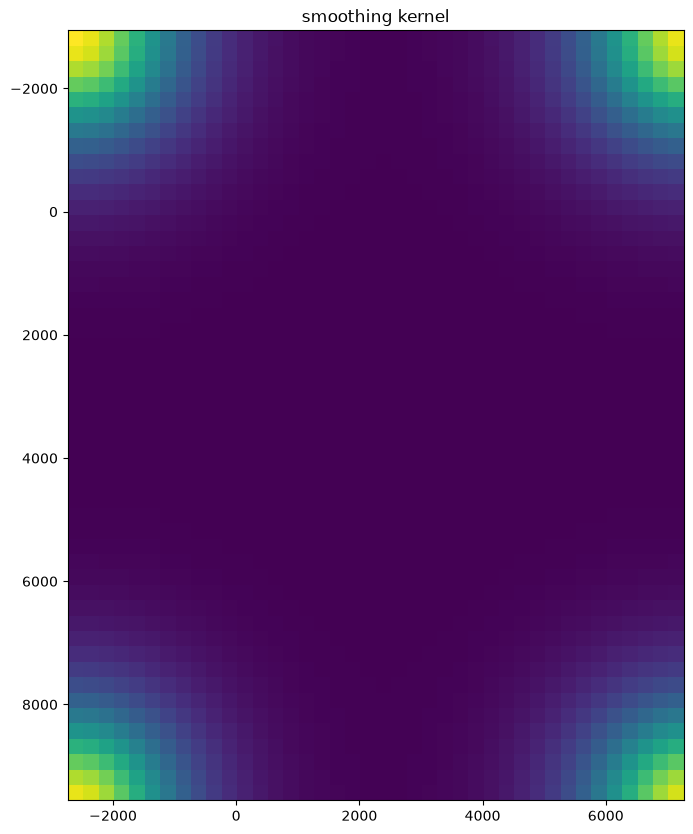

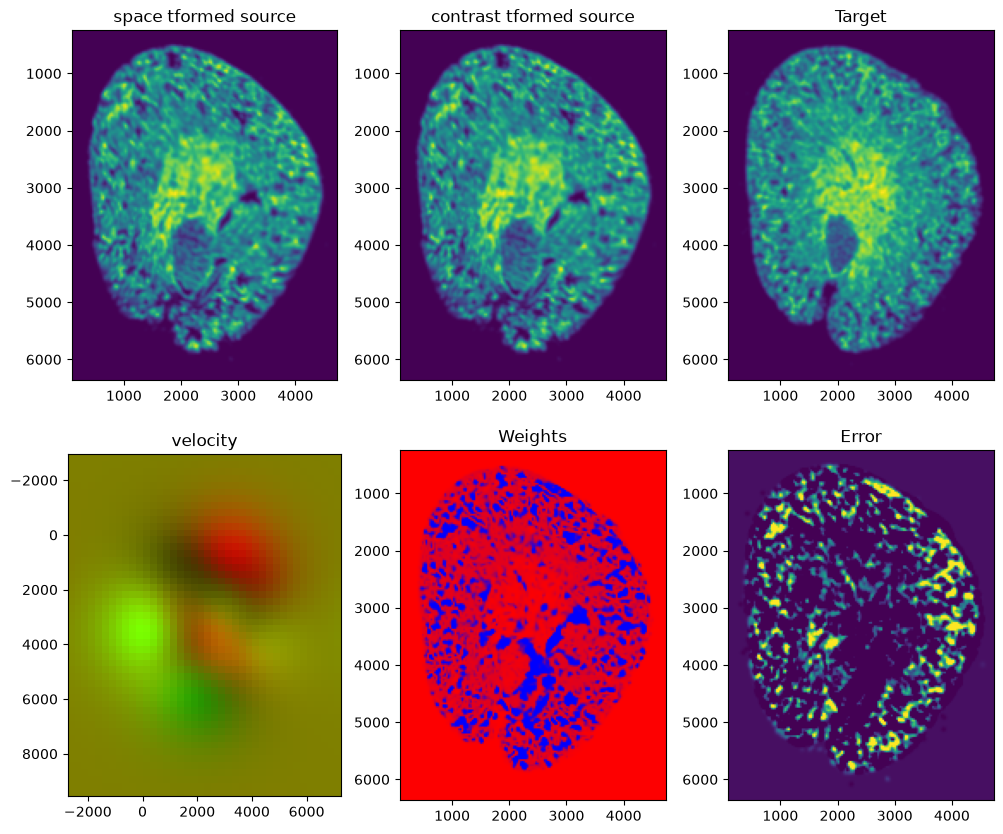

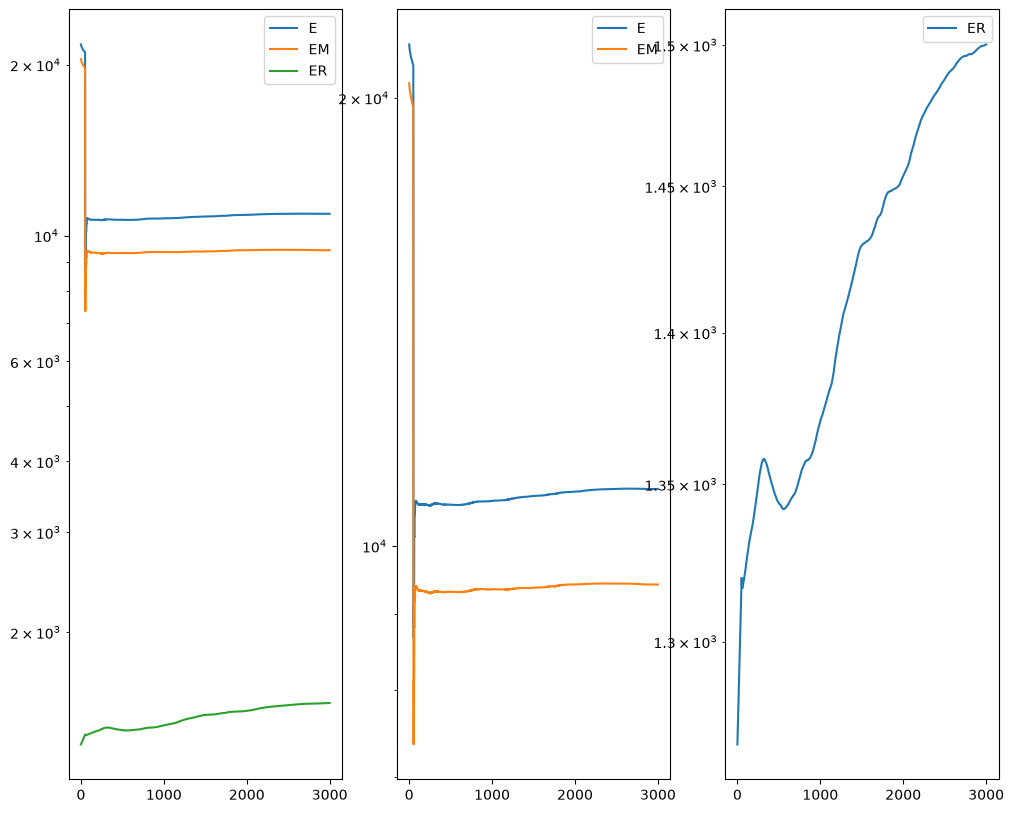

In [5]:
%%time
out = STalign.align_cells(xI, yI, xJ, yJ, dx=30, levels=((2,1000),(1,3000)),
                          mixture=None, prefit=False, device='cpu')

## After alignment

We apply the transform to the source cells. `STalign` uses (row, column) order, so we pass the points as (y, x) and swap them back.

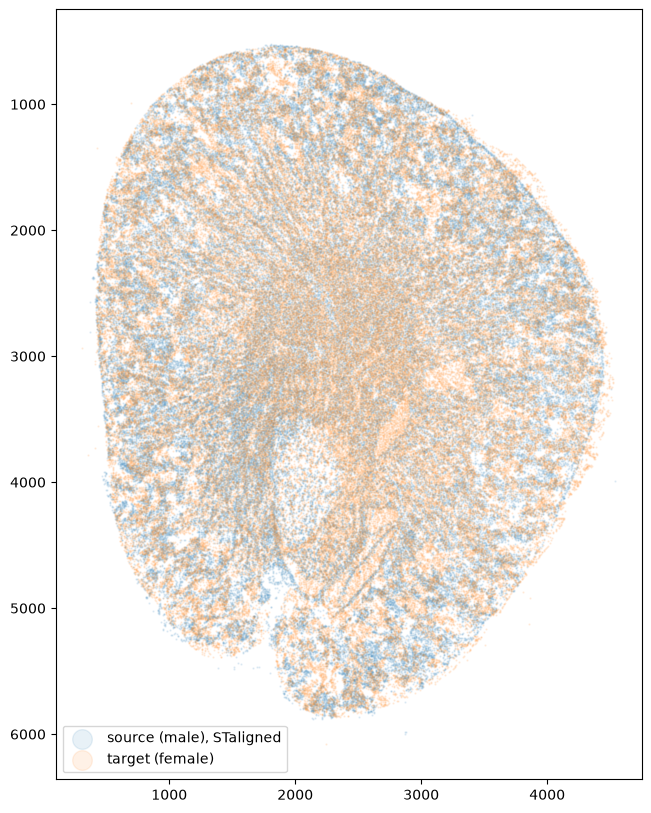

In [6]:
tpointsI = STalign.transform_points_source_to_target(out['xv'], out['v'], out['A'], np.stack([yI, xI], 1)).cpu().numpy()
xI_aligned = tpointsI[:,1]
yI_aligned = tpointsI[:,0]

fig,ax = plt.subplots()
ax.scatter(xI_aligned,yI_aligned,s=0.5,alpha=0.1, label='source (male), STaligned')
ax.scatter(xJ,yJ,s=0.5,alpha=0.1, label='target (female)')
ax.set_aspect('equal')
ax.invert_yaxis()
ax.legend(markerscale = 20, loc = 'lower left')

## Write out the results

We append the aligned positions to the original source data, both in the image pixel units of the target, so they can be used in place of its `x` and `y`, and in micrometers. We save them as a compressed `.csv.gz` file.

In [7]:
results = df1.assign(aligned_x = xI_aligned/um_per_px,
                     aligned_y = yI_aligned/um_per_px,
                     aligned_x_um = xI_aligned,
                     aligned_y_um = yI_aligned)
results.to_csv('../cartana_data/GSM7090410_cartana_sham_male_STalign_to_GSM7090415_cartana_sham_female_align_cells.csv.gz',
               compression='gzip', index=False)
results.head()

,cell,x,y,cluster,n_transcripts,density,elongation,area,avg_confidence,aligned_x,aligned_y,aligned_x_um,aligned_y_um
0,1,5905.766000,4884.044000,4,5,0.007945,5.859,629.3,0.9994,5215.722303,6257.965821,847.554874,1016.919446
1,2,5086.160000,5708.391250,5,8,0.011020,1.989,725.7,0.9999,4565.575292,7172.918637,741.905985,1165.599278
2,3,5556.215000,5281.355000,6,10,0.005935,2.592,1685.0,1.0000,4937.389106,6690.008583,802.325730,1087.126395
3,4,5017.552000,5799.638000,5,10,0.010640,3.218,940.2,1.0000,4515.110684,7274.851790,733.705486,1182.163416
4,5,6035.902857,4798.607143,5,7,0.007109,4.155,984.7,0.9992,5323.900946,6162.581790,865.133904,1001.419541
